In [1]:
# Cell 1: Imports
# reload guards let mid-session edits to the .py scripts take effect
# without restarting the kernel
import importlib

import numpy as np
import torch
import matplotlib.pyplot as plt

import train as train_mod
import model as model_mod
import gconvgru as gconvgru_mod
import train_gconvgru as train_gconvgru_mod
import viz as viz_mod
importlib.reload(train_mod)
importlib.reload(model_mod)
importlib.reload(gconvgru_mod)
importlib.reload(train_gconvgru_mod)   # after train_mod (it imports from train)
importlib.reload(viz_mod)              # after gconvgru_mod (it imports the model class)

from train import train, node_random_split, mae, rmse, bias, nse
from train_gconvgru import train_gconvgru_node_split
from model import BaselineGCN, ChebGCN
from gconvgru import GConvGRUModel
from viz import (plot_loss_curve, plot_parity, plot_spatial,
                 predict_full_field, plot_spatial_field)

torch.manual_seed(59)  # reproducibility

In [2]:
# Cell 2: Load real Delft3D-derived tensors (output of d3d_grid_processing.py)
# Assumes features.npz, edge_index.npy, node_index.npy, meta.json exist in DATA_DIR,
# produced by running d3d_grid_processing.py on the .nc trim-file.
from dataset import Delft3DDataset

DATA_DIR = "."  # change if the .npz / .npy / .json files live elsewhere

real_dataset = Delft3DDataset(
    feature_file=f"{DATA_DIR}/features.npz",
    edge_file=f"{DATA_DIR}/edge_index.npy",
    node_file=f"{DATA_DIR}/node_index.npy",
    meta_file=f"{DATA_DIR}/meta.json",
    normalize=True,
)

real_dataset.summary()

--------------- Dataset Summary ---------------
Timesteps : 10
Nodes     : 756,809
Features  : 6
Edges     : 3,022,810
Feature names:
   - DPS
   - S1
   - U1
   - V1
   - TAUKSI
   - TAUETA
-----------------------------------------------


In [3]:
# Cell 3: TEMPORAL-split training - switch between models
# GConvGRU is intentionally excluded here: it is recurrent and node-split only
# (it trains via train_gconvgru.py in Cell 7).
TEMPORAL_MODEL = "gcn"  # "gcn" or "cheb"

if TEMPORAL_MODEL == "gcn":
    model_temporal = BaselineGCN(in_channels=real_dataset.F)
elif TEMPORAL_MODEL == "cheb":
    model_temporal = ChebGCN(in_channels=real_dataset.F)
else:
    raise ValueError(f"Unknown TEMPORAL_MODEL: {TEMPORAL_MODEL}")

# loss_alpha=2: mild weighted MSE so active (eroding/depositing) cells count
# more than the ~78%-zero static seabed. scheduler="plateau": the previous
# 150-epoch run plateaued (val improving ~3e-7/epoch at fixed lr=1e-3); this
# halves the lr whenever val stalls for 5 epochs. Both knobs are tunable;
# loss_alpha=0, scheduler=None restores the original behavior.
history_temporal, results_temporal = train(
    model_temporal,
    real_dataset,
    split_mode="temporal",
    train_frac=0.80,
    val_frac=0.1,
    epochs=150,
    patience=10,
    loss_alpha=2,
    scheduler="plateau",
    checkpoint_path=f"best_temporal_{TEMPORAL_MODEL}.pt",
    history_path=f"history_temporal_{TEMPORAL_MODEL}.json",
    verbose=True,
)

Epoch 001 | train_loss=0.355760  val_loss=0.028672 | train_rmse=0.273992  val_rmse=0.097066 | lr=1.00e-03
Epoch 002 | train_loss=0.104455  val_loss=0.035938 | train_rmse=0.175619  val_rmse=0.123107 | lr=1.00e-03
Epoch 003 | train_loss=0.069575  val_loss=0.026600 | train_rmse=0.150592  val_rmse=0.072970 | lr=1.00e-03
Epoch 004 | train_loss=0.054935  val_loss=0.023496 | train_rmse=0.107026  val_rmse=0.060565 | lr=1.00e-03
Epoch 005 | train_loss=0.044923  val_loss=0.022980 | train_rmse=0.097752  val_rmse=0.063313 | lr=1.00e-03
Epoch 006 | train_loss=0.038812  val_loss=0.020542 | train_rmse=0.085006  val_rmse=0.042600 | lr=1.00e-03
Epoch 007 | train_loss=0.036936  val_loss=0.019710 | train_rmse=0.075846  val_rmse=0.035945 | lr=1.00e-03
Epoch 008 | train_loss=0.034704  val_loss=0.019511 | train_rmse=0.074646  val_rmse=0.035346 | lr=1.00e-03
Epoch 009 | train_loss=0.034317  val_loss=0.019282 | train_rmse=0.072262  val_rmse=0.034749 | lr=1.00e-03
Epoch 010 | train_loss=0.033599  val_loss=0.01

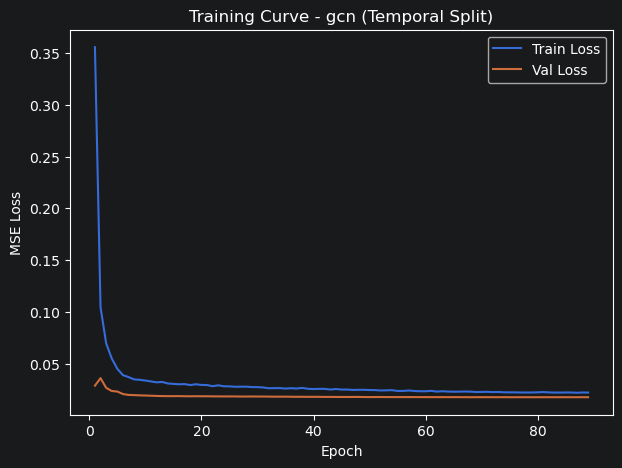

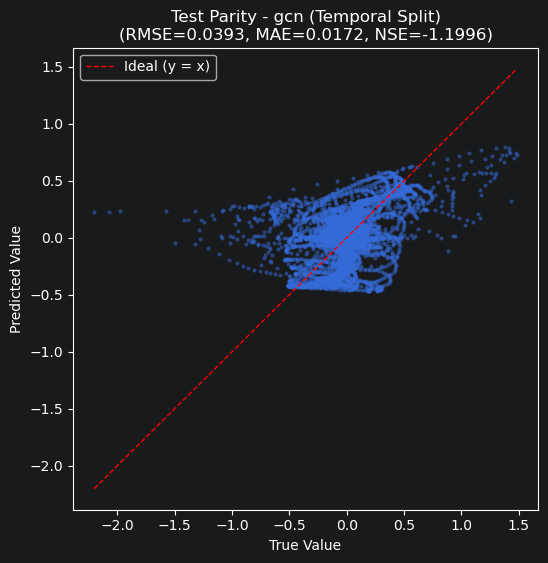

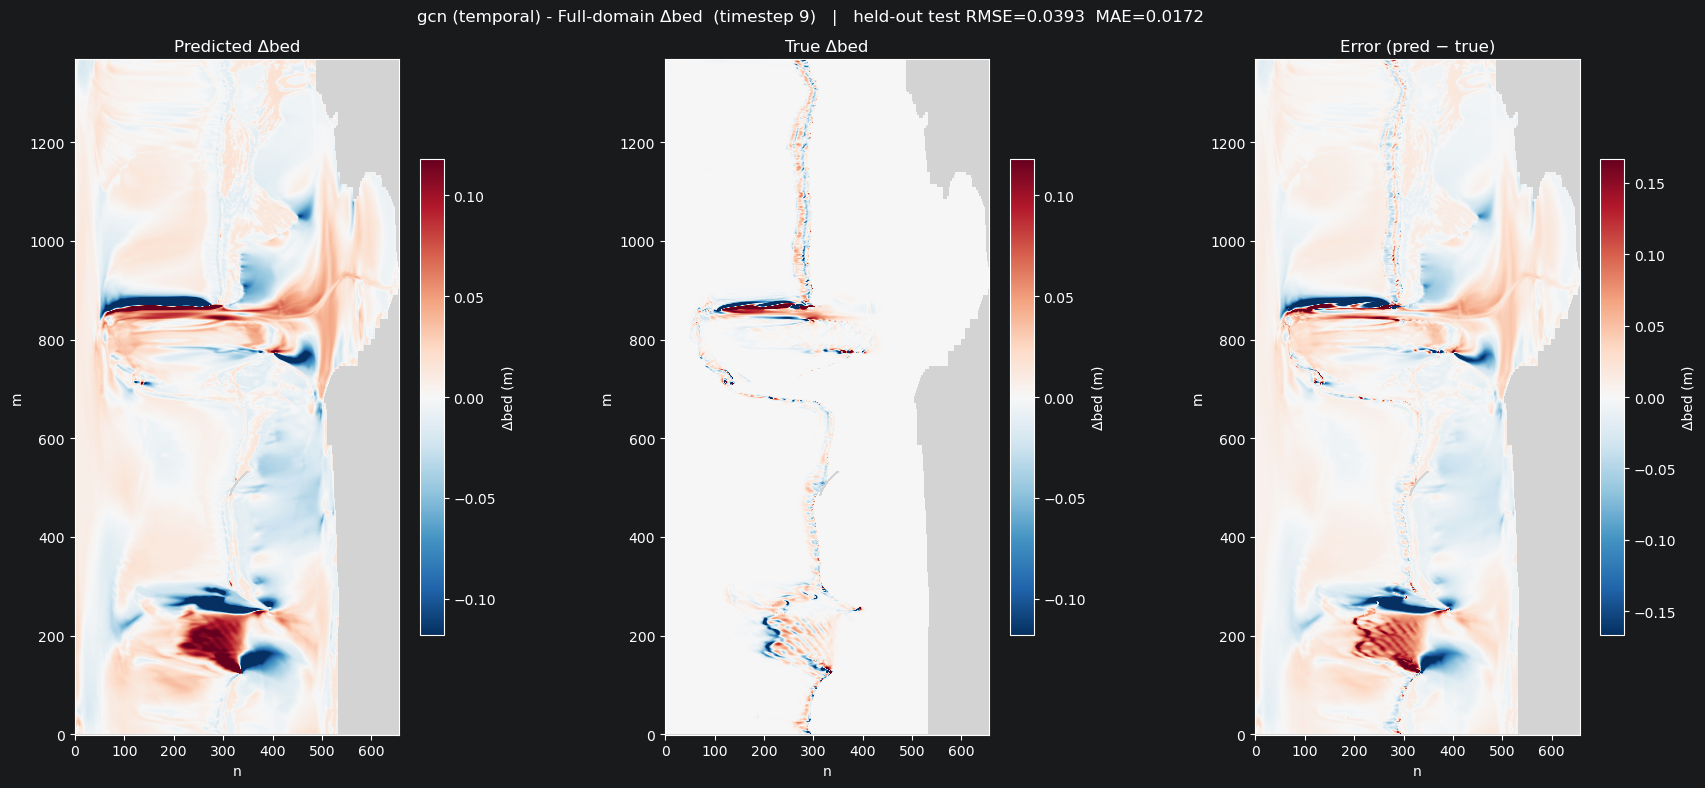

In [4]:
# Cell 4: Temporal-split outputs - loss curve, parity, full-domain spatial map
plot_loss_curve(history_temporal, f"Training Curve - {TEMPORAL_MODEL} (Temporal Split)")
plot_parity(results_temporal, f"Test Parity - {TEMPORAL_MODEL} (Temporal Split)")

# Full-domain spatial map, same diverging/robust rendering as the node-split map
# (Cell 6) for visual consistency. Temporal split holds out whole timesteps, so
# at a test timestep (default -1) the entire shown field is genuinely unseen.
y_pred_full_temporal = predict_full_field(model_temporal, real_dataset)
plot_spatial_field(y_pred_full_temporal, real_dataset, timestep_idx=-1,
                   results=results_temporal, title_prefix=f"{TEMPORAL_MODEL} (temporal) - ")

In [5]:
# Cell 5: NODE-split training - switch between models
# Mirrors Cell 3, but splits NODES (seed 42) instead of timesteps: every
# timestep is seen in every phase and only the node subset differs
# (transductive). The recurrent GConvGRU trains in Cell 7 with its own
# variables; Cell 6 displays this cell's model, Cell 8 displays GConvGRU.
NODE_MODEL = "gcn"  # "gcn" or "cheb"

if NODE_MODEL == "gcn":
    model_node = BaselineGCN(in_channels=real_dataset.F)
elif NODE_MODEL == "cheb":
    model_node = ChebGCN(in_channels=real_dataset.F)
else:
    raise ValueError(f"Unknown NODE_MODEL: {NODE_MODEL}")

# Same knobs as the temporal Cell 3: loss_alpha=2 (mild weighted MSE so
# active cells outweigh the ~78%-zero seabed), scheduler="plateau" (halve lr
# when val stalls for 5 epochs). loss_alpha=0, scheduler=None restores the
# original plain-MSE behavior.
history_node, results_node = train(
    model_node, real_dataset, split_mode="node",
    train_frac=0.70, val_frac=0.15, epochs=150, patience=10,
    loss_alpha=2, scheduler="plateau",
    checkpoint_path=f"best_node_{NODE_MODEL}.pt",
    history_path=f"history_node_{NODE_MODEL}.json",
    node_split_seed=42, verbose=True,
)

Node split -> train: 529,767  val: 113,521  test: 113,521 (of 756,809 nodes)
Epoch 001 | train_loss=0.227210  val_loss=0.072529 | train_rmse=0.200426  val_rmse=0.112593 | lr=1.00e-03
Epoch 002 | train_loss=0.061447  val_loss=0.044040 | train_rmse=0.122245  val_rmse=0.092982 | lr=1.00e-03
Epoch 003 | train_loss=0.050792  val_loss=0.033301 | train_rmse=0.105756  val_rmse=0.076880 | lr=1.00e-03
Epoch 004 | train_loss=0.039682  val_loss=0.029531 | train_rmse=0.091141  val_rmse=0.064259 | lr=1.00e-03
Epoch 005 | train_loss=0.036910  val_loss=0.027569 | train_rmse=0.083339  val_rmse=0.055545 | lr=1.00e-03
Epoch 006 | train_loss=0.035352  val_loss=0.026547 | train_rmse=0.077686  val_rmse=0.050647 | lr=1.00e-03
Epoch 007 | train_loss=0.033924  val_loss=0.025810 | train_rmse=0.074279  val_rmse=0.046978 | lr=1.00e-03
Epoch 008 | train_loss=0.032933  val_loss=0.025219 | train_rmse=0.071907  val_rmse=0.045257 | lr=1.00e-03
Epoch 009 | train_loss=0.031585  val_loss=0.024678 | train_rmse=0.069570  v

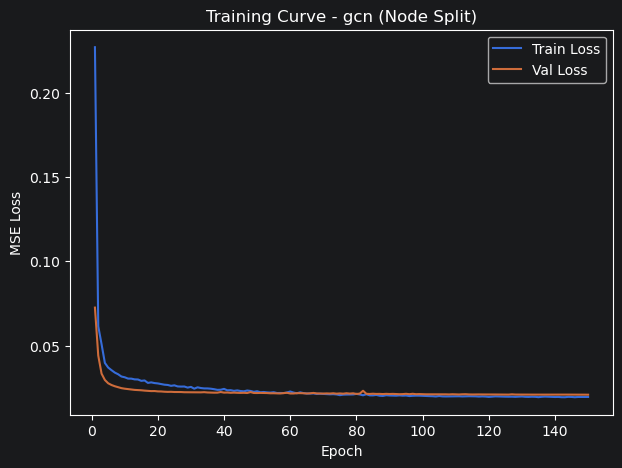

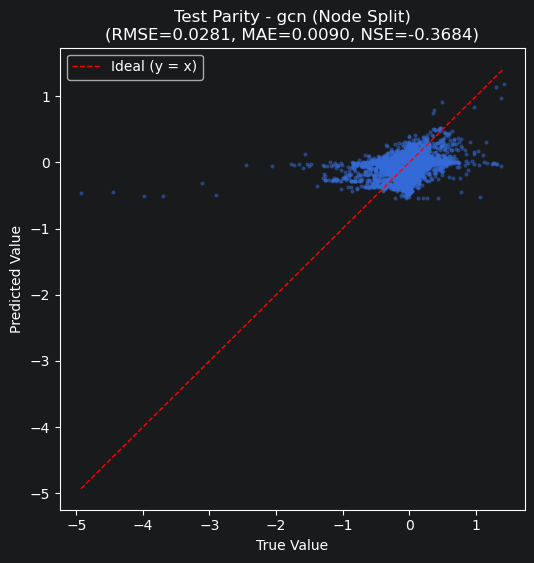

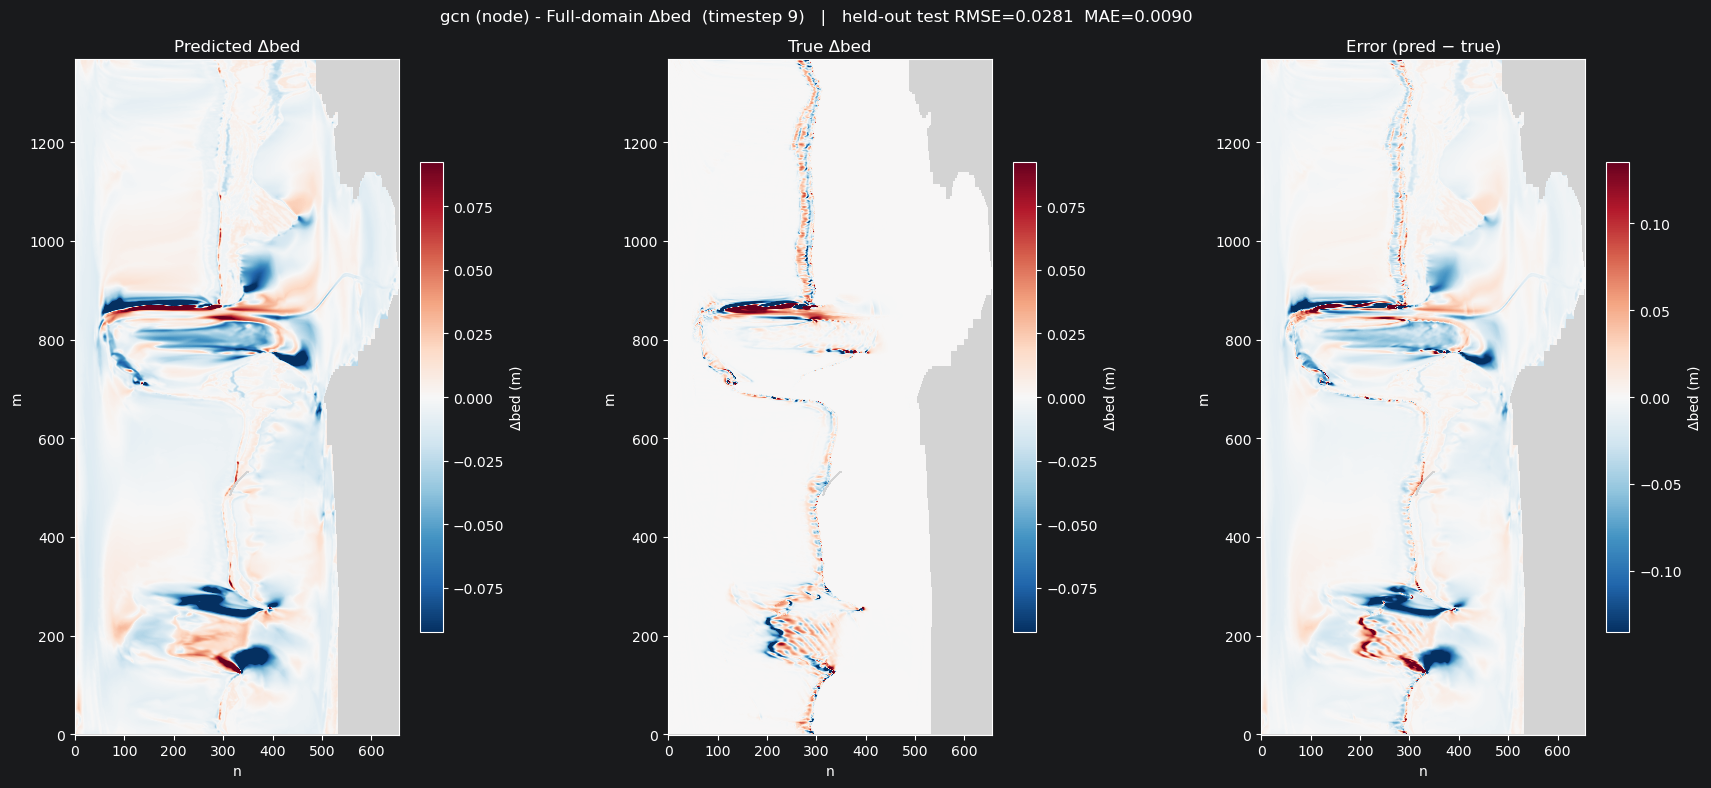

In [6]:
# Cell 6: Node-split outputs (static gcn/cheb) - loss curve, parity, spatial map
plot_loss_curve(history_node, f"Training Curve - {NODE_MODEL} (Node Split)")
plot_parity(results_node, f"Test Parity - {NODE_MODEL} (Node Split)")

# Full-domain spatial map. results_node only holds the scattered 15% held-out
# test nodes (incoherent under the random split), so we run the trained model
# over EVERY node to get a dense, readable field. The held-out test RMSE/MAE
# from results_node are still shown in the title as the honest metric.
y_pred_full = predict_full_field(model_node, real_dataset)
plot_spatial_field(y_pred_full, real_dataset, timestep_idx=-1,
                   results=results_node, title_prefix=f"{NODE_MODEL} (node) - ")

# Tip: change timestep_idx (2..9 have signal; t=0,1 are all-zero spin-up), or
# robust_pct to tighten/loosen the color scale.

In [7]:
# Cell 7: NODE-split training - recurrent GConvGRU (train_gconvgru.py)
# Uses the SAME node split as Cell 5 (seed 42 + node_random_split), so results
# are directly comparable with the static models. Own variables (model_ggru,
# history_ggru, results_ggru) so this cell and Cell 5 never overwrite each
# other's results — Cell 6 shows the static model, Cell 8 shows this one.

# dropout=0.0 / weight_decay=0.0: both nudge predictions toward zero on a
# near-zero target; no overfitting was observed (train ~= val).
model_ggru = GConvGRUModel(in_feats=real_dataset.F, dropout=0.0)

torch.manual_seed(42)
train_mask, val_mask, test_mask = node_random_split(
    real_dataset.N, val_frac=0.15, test_frac=0.15
)

# Anti-collapse settings (a plain-MSE 150-epoch run predicted ~0 everywhere):
#   loss_alpha=5      active cells dominate the gradient (weighted MSE)
#   lr=5e-3 + cosine  only 1 Adam step/epoch (one full-BPTT backward), so
#                     fewer-but-larger steps, decayed to lr/20 by the end
# val_every=5 skips 4 of 5 validation rollouts; patience counts validation
# events (5 events = up to 25 epochs without improvement). See
# train_gconvgru.py's docstring for the BPTT/memory/speed design.
history_ggru, results_ggru = train_gconvgru_node_split(
    model_ggru, real_dataset, train_mask, val_mask, test_mask,
    lr=5e-3, weight_decay=0.0, epochs=150, patience=10, val_every=5,
    loss_alpha=5, scheduler="cosine",
    checkpoint_path="best_node_gconvgru.pt", verbose=True,
)

Epoch 001 | train_loss=0.042106  train_rmse=0.108099 | lr=5.00e-03
Epoch 002 | train_loss=0.040152  train_rmse=0.097352 | lr=5.00e-03
Epoch 003 | train_loss=0.032433  train_rmse=0.074803 | lr=5.00e-03
Epoch 004 | train_loss=0.030129  train_rmse=0.056300 | lr=4.99e-03
Epoch 005 | train_loss=0.030538  train_rmse=0.052721 | val_loss=0.032895  val_rmse=0.050354 | lr=4.99e-03
Epoch 006 | train_loss=0.029768  train_rmse=0.049694 | lr=4.98e-03
Epoch 007 | train_loss=0.028463  train_rmse=0.044325 | lr=4.97e-03
Epoch 008 | train_loss=0.027655  train_rmse=0.040855 | lr=4.97e-03
Epoch 009 | train_loss=0.027440  train_rmse=0.041096 | lr=4.96e-03
Epoch 010 | train_loss=0.027419  train_rmse=0.042512 | val_loss=0.030179  val_rmse=0.043018 | lr=4.95e-03
Epoch 011 | train_loss=0.027213  train_rmse=0.042355 | lr=4.94e-03
Epoch 012 | train_loss=0.026753  train_rmse=0.040064 | lr=4.93e-03
Epoch 013 | train_loss=0.026320  train_rmse=0.037463 | lr=4.91e-03
Epoch 014 | train_loss=0.026148  train_rmse=0.03645

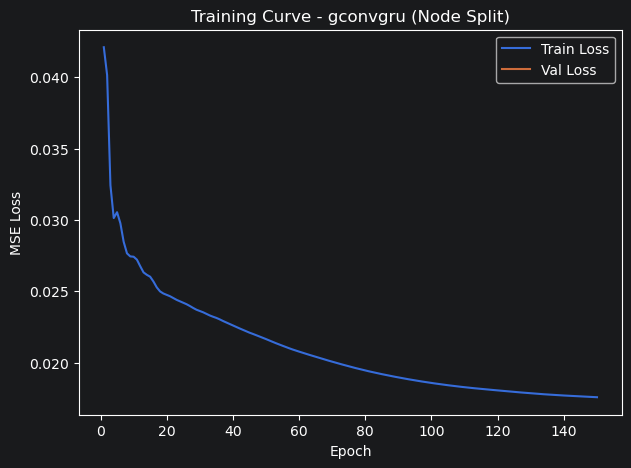

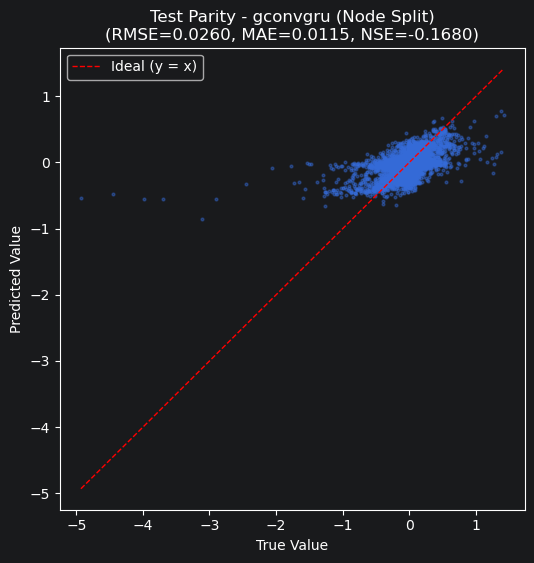

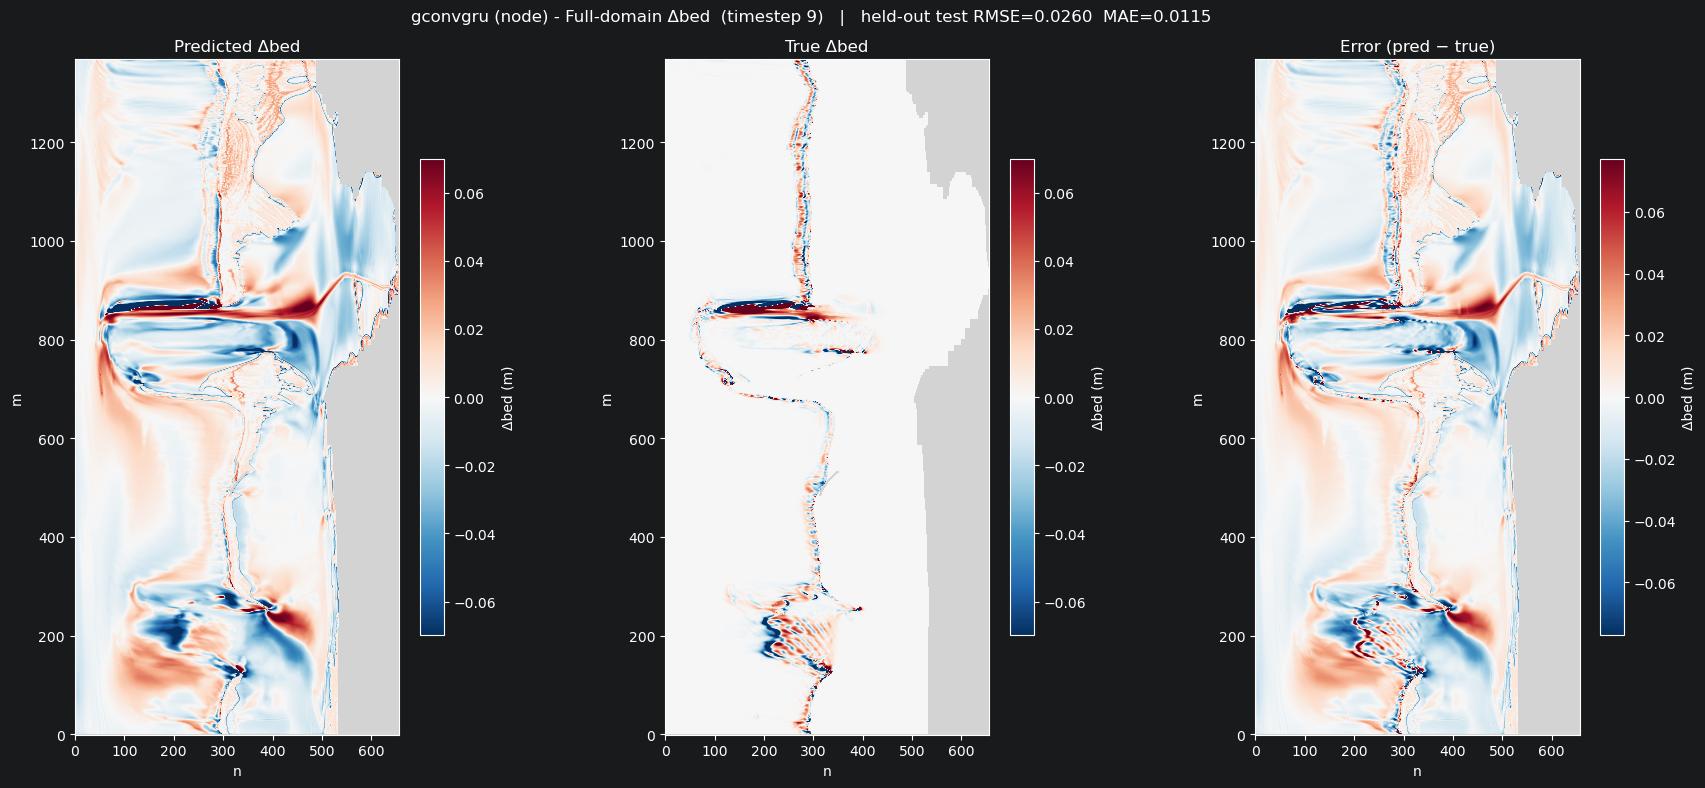

In [8]:
# Cell 8: GConvGRU node-split outputs - loss curve, parity, full-domain spatial map
# Same rendering as Cell 6, so the static-vs-recurrent comparison is direct.
plot_loss_curve(history_ggru, "Training Curve - gconvgru (Node Split)")
plot_parity(results_ggru, "Test Parity - gconvgru (Node Split)")

# Full-domain spatial map: run the trained recurrent model over EVERY node
# (predict_full_field threads h1/h2 across timesteps automatically) — the
# held-out test RMSE/MAE from results_ggru stay in the title as the honest metric.
y_pred_full_ggru = predict_full_field(model_ggru, real_dataset)
plot_spatial_field(y_pred_full_ggru, real_dataset, timestep_idx=-1,
                   results=results_ggru, title_prefix="gconvgru (node) - ")

# Tip: change timestep_idx (2..9 have signal; t=0,1 are all-zero spin-up), or
# robust_pct to tighten/loosen the color scale.